# Tutorial 2 — Single-cell + spatial integration with PIANO

Integrate Allen mouse whole-brain 10Xv3 scRNA-seq with one MERFISH section into a shared latent space.

## Steps

1. Load one scRNA-seq `.h5ad` and one MERFISH `.h5ad`
2. Train PIANO with `modality` as the batch covariate
3. Compare PCA vs PIANO UMAPs (modality mixing vs subclass conservation)

## Data

Download from [https://PLACEHOLDER_DATA_URL](https://PLACEHOLDER_DATA_URL) and point `DATA_DIR` at that folder. You need these two files:

- `allen_mouse_scrnaseq_merfish_panel_250_per_subclass.h5ad` — 10Xv3 cells, up to 250 per `Subclass`, only the Subclasses found in the MERFISH section
- `allen_mouse_merfish_638850_section_1199651033.h5ad` — all QC-passed cells of one coronal section (cortex, hippocampus, thalamus); section coordinates in `obs["x"]`, `obs["y"]`

MERFISH measures a 500-gene panel; the scRNA-seq file is already restricted to those same 500 genes, so both files share `var_names`. Counts are in `.X`. Required `obs` columns: `modality`, `Subclass`.

The last section shows how these files were built from the raw Allen data if you want to reproduce that step.

## 1. Setup

In [1]:
# Google Colab only (skip on your own machine): install PIANO and mount Google Drive.
# Uncomment, run once, then point DATA_DIR / OUT_DIR below at your Drive folder.
# !pip install -q piano-integration
# from google.colab import drive
# drive.mount("/content/drive")

In [2]:
from pathlib import Path
import pickle

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # Needed for reproducible GPU training; set before importing piano
os.environ["TQDM_DISABLE"] = "1"  # Hide per-epoch progress bars
from piano import Composer
import warnings
warnings.filterwarnings("ignore")

DATA_DIR = Path("/jukebox/krienen/lab_members/annita/piano/results/sc_spatial_mouse")  # folder with the two downloaded h5ads
# DATA_DIR = Path("data/sc_spatial_mouse")  # folder with the two downloaded h5ads
OUT_DIR = Path("../results/sc_spatial_mouse")
# DATA_DIR = Path("/content/drive/MyDrive/piano_data/sc_spatial_mouse")  # Google Colab
# OUT_DIR = Path("/content/drive/MyDrive/piano_results/sc_spatial_mouse")  # Google Colab
OUT_DIR.mkdir(parents=True, exist_ok=True)

N_PER_SUBCLASS = 250
SECTION = "1199651033"  # MERFISH coronal section through cortex, hippocampus, and thalamus

/jukebox/krienen/lab_members/annita/venvs/piano-integration/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load scRNA-seq and MERFISH

Pass them to `Composer` as a list. PIANO does not concatenate them for training.

In [3]:
%%time
scrna = sc.read_h5ad(DATA_DIR / f"allen_mouse_scrnaseq_merfish_panel_{N_PER_SUBCLASS}_per_subclass.h5ad")
merfish = sc.read_h5ad(DATA_DIR / f"allen_mouse_merfish_638850_section_{SECTION}.h5ad")
assert (scrna.var_names == merfish.var_names).all()  # same 500-gene panel, same order
scrna, merfish

CPU times: user 120 ms, sys: 78.7 ms, total: 199 ms
Wall time: 1.37 s


(AnnData object with n_obs × n_vars = 48420 × 500
     obs: 'Class', 'Subclass', 'donor_label', 'region_of_interest_acronym', 'modality',
 AnnData object with n_obs × n_vars = 93471 × 500
     obs: 'Class', 'Subclass', 'color_hex_subclass', 'brain_section_barcode', 'CCF_level1', 'x', 'y', 'modality')

## 3. Train PIANO

`modality` is the covariate to correct. The panel is already shared and small, so `n_top_genes=-1` keeps all 500 genes instead of selecting HVGs. `run_pipeline()` trains the model and writes checkpoints to `OUT_DIR`.

In [4]:
#@title Helper: send training details to a log file (run this cell)
# Helper: send per-epoch losses and torch.compile autotuning messages to a log file, keep other output in the cell
import contextlib
import logging
import re
import sys

class _LineRouter:
    # Send each complete line to the log if it matches, else to the original stream
    def __init__(self, stream, log, pattern):
        self.stream, self.log, self.pattern, self.buffer = stream, log, pattern, ""

    def write(self, text):
        self.buffer += text
        *lines, self.buffer = self.buffer.split("\n")
        for line in lines:
            (self.log if self.pattern.match(line) else self.stream).write(line + "\n")
        return len(text)

    def flush(self):
        self.stream.flush()
        self.log.flush()

@contextlib.contextmanager
def log_training_details(path, pattern=r"Epoch (Total|improvement)|(SingleProcess )?AUTOTUNE|  \S|[A-Z]\d{4} .*torch/_"):
    """Write per-epoch losses, torch.compile autotuning and torch log messages to `path` instead of the cell output."""
    loggers = [lg for name, lg in logging.Logger.manager.loggerDict.items() if name.startswith("torch") and isinstance(lg, logging.Logger)]
    handlers = [h for lg in loggers for h in lg.handlers if type(h) is logging.StreamHandler]  # Plain handlers only; torch's trace handler stays off
    old = sys.stdout, sys.stderr, [h.stream for h in handlers]
    with open(path, "w") as log:
        sys.stdout, sys.stderr = _LineRouter(sys.stdout, log, re.compile(pattern)), _LineRouter(sys.stderr, log, re.compile(pattern))
        for h in handlers:
            h.setStream(sys.stderr)
        try:
            yield
        finally:
            for r in (sys.stdout, sys.stderr):
                if r.buffer:
                    r.stream.write(r.buffer)
            sys.stdout, sys.stderr = old[0], old[1]
            for h, s in zip(handlers, old[2]):
                h.setStream(s)

In [5]:
%%time
# Initialize the Composer object ("pianist") for scRNA-seq + MERFISH integration
pianist = Composer(
    adata=[scrna, merfish],                         # List of AnnData objects, one per modality
    categorical_covariate_keys=["modality"],        # Specify "modality" as the categorical covariate batch to correct
    n_top_genes=-1,                                 # Use all genes; both files are already restricted to the MERFISH panel
    memory_mode="GPU",                              # Run model training on the GPU
    compile_model=True,                             # Compile the PIANO model before training, speeds up training!
    samples_per_class=None,                         # Do not subsample further
    adversarial=True,                               # Use adversarial loss for integration
    max_epochs=200,                                 # Number of epochs to train
    min_kld_weight=0.0,                             # Initial KLD (KL-divergence) weight for VAE warmup
    max_kld_weight=0.25,                            # Maximum KLD weight during training
    random_seed=0,                                  # Set the seed for reproducible results
    run_name="mouse_sc_merfish",                    # Run name for output folders/checkpoints
    outdir=str(OUT_DIR),                            # Output directory for results
)

# Run PIANO full pipeline: feature setup, model training, result export, etc.
with log_training_details(OUT_DIR / "training_log.txt"):  # Per-epoch losses and autotuning details go to this file
    pianist.run_pipeline()

with open(OUT_DIR / "pianist.pkl", "wb") as f:
    pickle.dump(pianist, f)

Preparing data with highly_variable_genes flavor = seurat_v3, -1 HVGs (-1 = all HVGs if selected before passing into Composer), batch key = None
Encoding covariates with: ({'modality': {'Unknown': -1, 'MERFISH': np.int64(0), 'scRNA-seq': np.int64(1)}}, {})
Preparing training data using 2 adatas: [AnnData object with n_obs × n_vars = 48420 × 500
    obs: 'Class', 'Subclass', 'donor_label', 'region_of_interest_acronym', 'modality', AnnData object with n_obs × n_vars = 93471 × 500
    obs: 'Class', 'Subclass', 'color_hex_subclass', 'brain_section_barcode', 'CCF_level1', 'x', 'y', 'modality']


Preparing model with input size: 500, distribution: nb, categorical_covariate_keys: ['modality'], continuous_covariate_keys: [], adversarial: True
Training started using device=cuda and memory_mode=GPU with up to 200 epochs and random seed 0 for run version: mouse_sc_merfish


Model compiling for up to 10x faster training


No improvement in the last 5 epochs. Early stopping
Best model at epoch 90 saved to ../results/sc_spatial_mouse/checkpoints/model_checkpoint.pt


CPU times: user 3min 59s, sys: 4.38 s, total: 4min 4s
Wall time: 4min 36s


## 4. PCA vs PIANO UMAPs

Concatenate only for plotting. PCA uses the same 500 genes PIANO trained on. Expected pattern: PCA separates scRNA-seq from MERFISH; PIANO mixes the two and keeps `Subclass` structure.

The integrated object (with `X_piano` and the MERFISH coordinates) is saved for Tutorial 3.

In [6]:
%%time
combined = ad.concat(pianist.adata, keys=["scRNA-seq", "MERFISH"], index_unique="-", join="outer")  # outer keeps MERFISH-only obs (x, y)
combined.obsm["X_piano"] = pianist.get_latent_representation(combined) # get the latent representation of the combined data

# UMAP on expression data
pca_ad = combined.copy()
sc.pp.normalize_total(pca_ad, target_sum=1e4)
sc.pp.log1p(pca_ad)
sc.pp.pca(pca_ad, n_comps=50)
sc.pp.neighbors(pca_ad, n_neighbors=15, n_pcs=50, use_rep="X_pca", random_state=0)
sc.tl.umap(pca_ad, random_state=0)
combined.obsm["X_umap_pca"] = pca_ad.obsm["X_umap"]
del pca_ad

# UMAP on PIANO latent space
sc.pp.neighbors(combined, n_neighbors=15, use_rep="X_piano", random_state=0)
sc.tl.umap(combined, random_state=0)
combined.obsm["X_umap_piano"] = combined.obsm["X_umap"]
combined.write_h5ad(OUT_DIR / "mouse_sc_merfish_integrated.h5ad")
combined

Retrieving latent space with shape (141891, 32)


CPU times: user 8min 12s, sys: 1.54 s, total: 8min 14s
Wall time: 3min 59s


AnnData object with n_obs × n_vars = 141891 × 500
    obs: 'Class', 'Subclass', 'donor_label', 'region_of_interest_acronym', 'modality', 'color_hex_subclass', 'brain_section_barcode', 'CCF_level1', 'x', 'y'
    uns: 'neighbors', 'umap'
    obsm: 'X_piano', 'X_umap_pca', 'X_umap', 'X_umap_piano'
    obsp: 'distances', 'connectivities'

In [7]:
combined = sc.read_h5ad(OUT_DIR / "mouse_sc_merfish_integrated.h5ad")

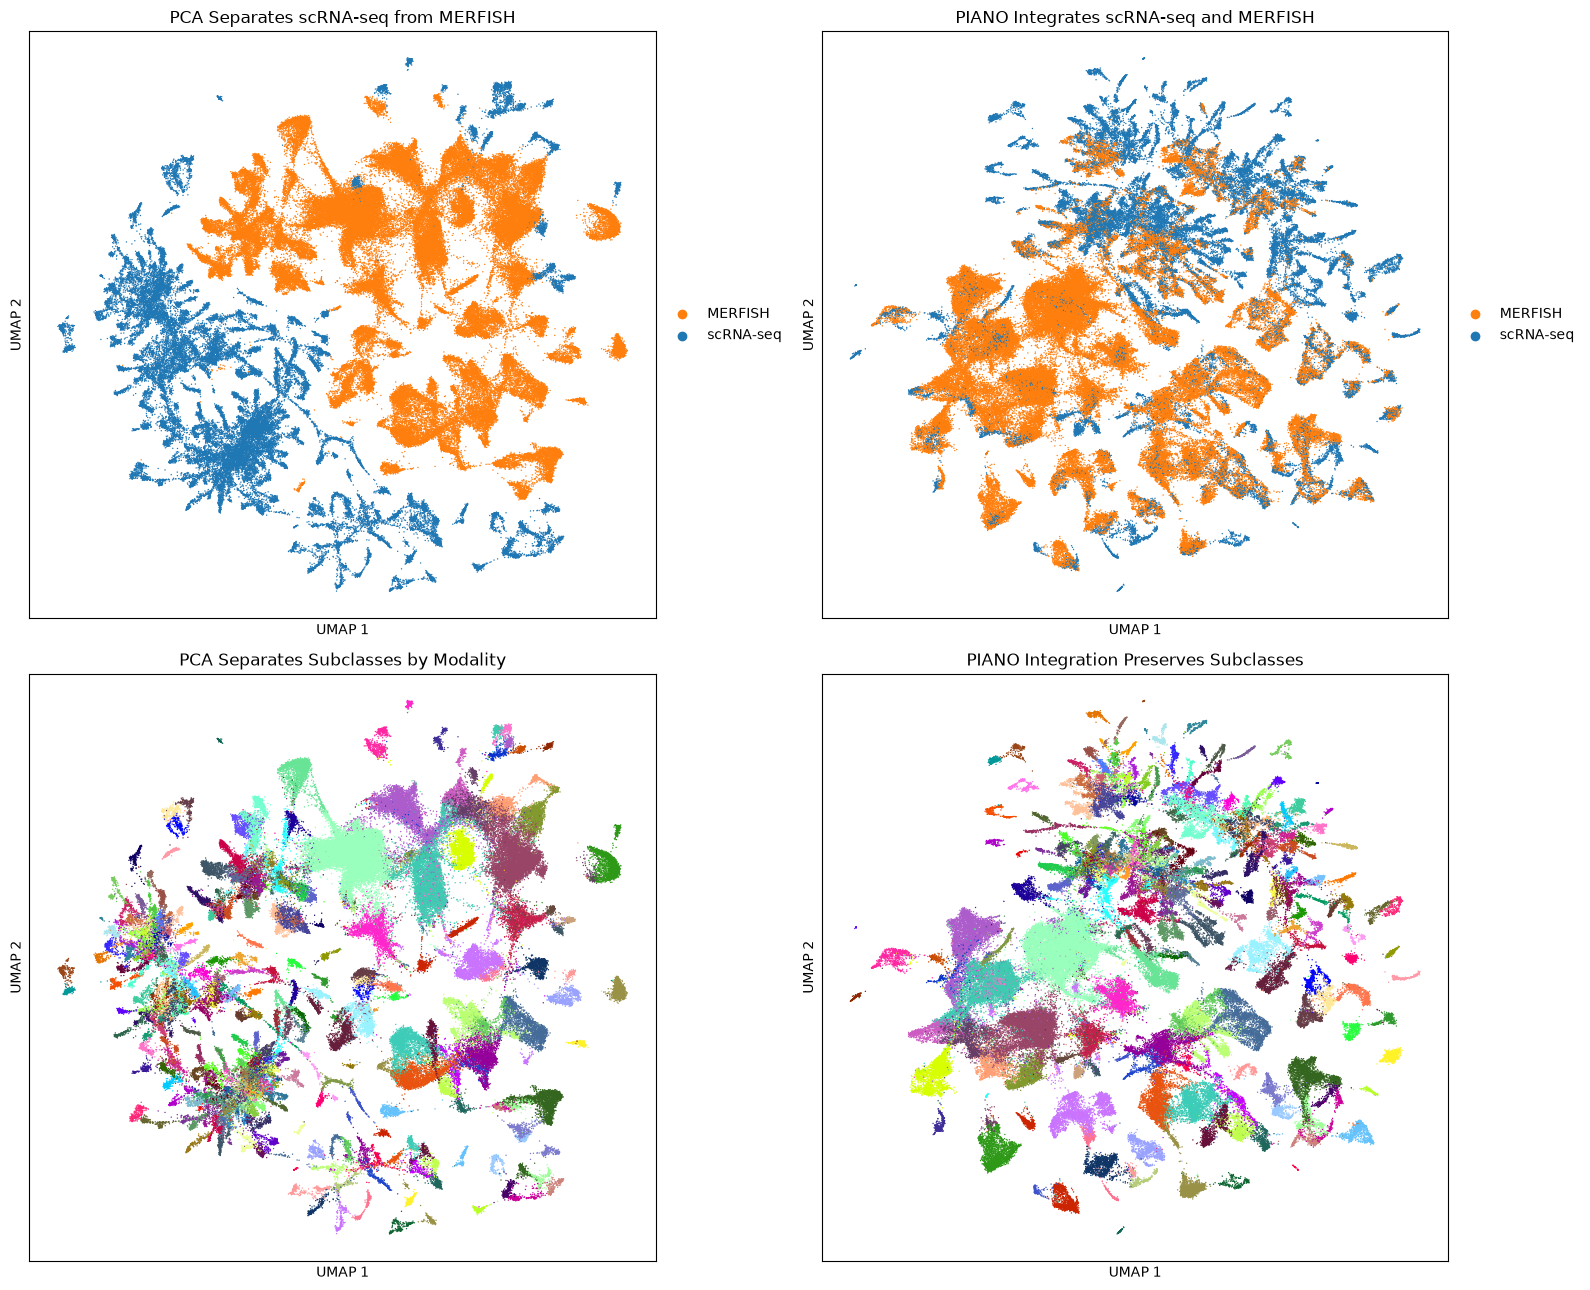

In [8]:
%matplotlib inline

plot_ad = combined[np.random.default_rng(0).permutation(combined.n_obs)].copy()
modality_palette = {"scRNA-seq": "#1f77b4", "MERFISH": "#ff7f0e"}
subclass_palette = dict(merfish.obs.drop_duplicates("Subclass").set_index("Subclass")["color_hex_subclass"])  # Allen subclass colors

panels = [
    ("X_umap_pca", "modality", modality_palette, "right margin", "PCA Separates scRNA-seq from MERFISH"),
    ("X_umap_piano", "modality", modality_palette, "right margin", "PIANO Integrates scRNA-seq and MERFISH"),
    ("X_umap_pca", "Subclass", subclass_palette, "none", "PCA Separates Subclasses by Modality"),
    ("X_umap_piano", "Subclass", subclass_palette, "none", "PIANO Integration Preserves Subclasses"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for ax, (basis, color, palette, legend_loc, title) in zip(axes.ravel(), panels):
    plot_ad.obsm["X_umap"] = plot_ad.obsm[basis]
    sc.pl.umap(plot_ad, color=color, palette=palette, ax=ax, show=False, title=title, legend_loc=legend_loc, size=4, frameon=True)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")


fig.tight_layout()
fig.savefig(OUT_DIR / "pca_vs_piano_umap.png", dpi=200, bbox_inches="tight")
plt.show()

## Optional: rebuild the processed files

Skip this if you downloaded the two `.h5ad` files above. The cell below is the preprocessing we used.

It needs the raw Allen data (not required for the tutorial itself):

- `WMB-10Xv3-*-raw.h5ad` — Allen whole mouse brain 10Xv3 scRNA-seq, one file per region, raw counts in `.X`
- `mouse_638850_registered_082725.h5ad` — Allen MERFISH brain 638850, registered to CCF, with MapMyCells labels

Set `SC_DIR` and `MERFISH_H5AD`, then run it. Output is written to `DATA_DIR`.

In [ ]:
import pandas as pd
from scipy.sparse import csr_matrix
# Raw Allen mouse whole-brain data: 10Xv3 scRNA-seq (one h5ad per region) and one registered MERFISH brain
SC_DIR = Path("/path/to/allen_wmb_10x_raw_h5ads")  # WMB-10Xv3-*-raw.h5ad
MERFISH_H5AD = Path("/path/to/mouse_638850_registered_082725.h5ad")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# --- MERFISH: one section, QC-passed and CCF-registered cells, no Blank probes ---
src = sc.read_h5ad(MERFISH_H5AD, backed="r")
obs = src.obs
keep = obs["qc_pass"].astype(bool) & obs["x_CCF"].notna() & (obs["brain_section_barcode"].astype(str) == SECTION)
panel = np.array([g for g in src.var_names if not g.startswith("Blank")])
merfish = src[keep.to_numpy(), panel].to_memory()
merfish.X = csr_matrix(merfish.X, dtype=np.uint16)
merfish.obs = pd.DataFrame({
    "Class": merfish.obs["hrc_mmc_class_name"].astype(str),
    "Subclass": merfish.obs["hrc_mmc_subclass_name"].astype(str),
    "color_hex_subclass": merfish.obs["hrc_mmc_subclass_color"].astype(str),
    "brain_section_barcode": merfish.obs["brain_section_barcode"].astype(str),
    "CCF_level1": merfish.obs["CCF_level1"].astype(str),
    "x": merfish.obs["x"].to_numpy(),  # section coordinates; obs columns are kept by ad.concat(join="outer")
    "y": merfish.obs["y"].to_numpy(),
    "modality": "MERFISH",
}, index=merfish.obs_names)
merfish.var = pd.DataFrame(index=panel)
merfish.obs_names = merfish.obs_names.astype(object)  # plain str index; pandas-3 string indexes do not write with anndata defaults
merfish.uns = {}
merfish.obsm.clear()
merfish.layers.clear()
merfish.write_h5ad(DATA_DIR / f"allen_mouse_merfish_638850_section_{SECTION}.h5ad")
print("MERFISH", merfish.shape, merfish.obs["Subclass"].nunique(), "subclasses")
del src

# --- scRNA-seq: 10Xv3 cells from the Subclasses in this section, up to N_PER_SUBCLASS each, panel genes only ---
sc_files = sorted(SC_DIR.glob("WMB-10Xv3-*-raw.h5ad"))
sc_obs = pd.concat([sc.read_h5ad(p, backed="r").obs[["Subclass"]].assign(file=p.name) for p in sc_files])
sc_obs = sc_obs[sc_obs["Subclass"].isin(set(merfish.obs["Subclass"]))]
rng = np.random.default_rng(0)
picked = sc_obs.groupby("Subclass", observed=True, group_keys=False).apply(
    lambda df: df.iloc[rng.choice(len(df), size=min(len(df), N_PER_SUBCLASS), replace=False)]
)

parts = []
for p in sc_files:
    src = sc.read_h5ad(p, backed="r")
    cells = np.sort(src.obs_names.get_indexer(picked.index[picked["file"] == p.name]))
    if len(cells) == 0:
        continue
    part = src[cells, panel].to_memory()
    part.obs = part.obs[["Class", "Subclass", "donor_label", "region_of_interest_acronym"]].astype(str)
    parts.append(part)
    del src
scrna = ad.concat(parts)
assert scrna.X.max() < np.iinfo(np.uint16).max
scrna.X = csr_matrix(scrna.X, dtype=np.uint16)
scrna.obs["modality"] = "scRNA-seq"
scrna.obs_names = scrna.obs_names.astype(object)
scrna.obs.index.name = None
scrna.write_h5ad(DATA_DIR / f"allen_mouse_scrnaseq_merfish_panel_{N_PER_SUBCLASS}_per_subclass.h5ad")
print("scRNA-seq", scrna.shape, scrna.obs["Subclass"].nunique(), "subclasses")